# 1. Comparison models: XGB and ENet 80/20 results

This notebook compares saved `.h5` outputs across:

- `results_xgb/`
- `res_xgb_zbig/`
- `results_enet/`
- `res_enet_zbig/`

It scans all result files, prints concise summaries, creates clean plots, applies configurable thresholds for "well predicted" proteins, and builds three horizontal partition plots showing which run is best per protein according to Pearson, cosine similarity, and MSE.

In [5]:
# >>> pRNA figure routing (added by the pRNA update; keep as the first code cell)
# Every figure is shown inline. Every file written with savefig (png, pdf, svg) is redirected to
# figures_pdf/<notebook name>/ next to this notebook; sub-folders of the original path are preserved.
import os as _fig_os
from pathlib import Path as _FigPath
import matplotlib as _fig_mpl
import matplotlib.pyplot as _fig_plt
from matplotlib.figure import Figure as _FigFigure

NOTEBOOK_NAME = "1. comparison_models"
FIG_DIR = (_FigPath.cwd() / "figures_pdf" / NOTEBOOK_NAME).resolve()
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _route_figure_path(fname):
    p = _FigPath(_fig_os.fspath(fname))
    full = p if p.is_absolute() else (_FigPath.cwd() / p)
    try:
        full.resolve().relative_to(FIG_DIR)
        return fname                                  # already inside this notebook's figure folder
    except ValueError:
        pass
    try:
        rel = _FigPath(_fig_os.path.relpath(full.resolve(), _FigPath.cwd()))
    except ValueError:                                # e.g. another drive on Windows
        rel = _FigPath(p.name)
    parts = [x for x in rel.parts if x not in ("..", ".", "figures_pdf", NOTEBOOK_NAME)]
    target = FIG_DIR.joinpath(*parts) if parts else FIG_DIR / p.name
    target.parent.mkdir(parents=True, exist_ok=True)
    return target


if not getattr(_FigFigure.savefig, "_prna_routed", False):
    _fig_orig_savefig = _FigFigure.savefig

    def _fig_routed_savefig(self, fname, *args, **kwargs):
        if isinstance(fname, (str, bytes, _FigPath)) or hasattr(fname, "__fspath__"):
            fname = _route_figure_path(fname)
        return _fig_orig_savefig(self, fname, *args, **kwargs)

    _fig_routed_savefig._prna_routed = True
    _FigFigure.savefig = _fig_routed_savefig

    _fig_orig_close = _fig_plt.close

    def _fig_close_and_show(fig=None):
        """Display figures that are closed before Jupyter could render them, then close."""
        import inspect as _fig_inspect
        _caller = _fig_inspect.currentframe().f_back
        _caller_mod = (_caller.f_globals.get("__name__", "") if _caller is not None else "")
        if _caller_mod.startswith(("matplotlib", "ipykernel")):   # backend housekeeping, not user code
            return _fig_orig_close(fig)
        if "inline" in str(_fig_mpl.get_backend()).lower():
            from IPython.display import display as _fig_display
            open_nums = set(_fig_plt.get_fignums())
            if fig is None:
                figs = [_fig_plt.gcf()] if open_nums else []
            elif isinstance(fig, str) and fig == "all":
                figs = [_fig_plt.figure(n) for n in sorted(open_nums)]
            elif isinstance(fig, _FigFigure):
                figs = [fig] if getattr(fig, "number", None) in open_nums else []
            elif isinstance(fig, int):
                figs = [_fig_plt.figure(fig)] if fig in open_nums else []
            else:
                figs = []
            for _f in figs:
                if not getattr(_f, "_prna_displayed", False):
                    _f._prna_displayed = True
                    _fig_display(_f)
        return _fig_orig_close(fig)

    _fig_plt.close = _fig_close_and_show

    _fig_orig_show = _fig_plt.show

    def _fig_show_and_mark(*args, **kwargs):
        for _n in _fig_plt.get_fignums():                    # shown now -> never re-displayed on close
            _fig_plt.figure(_n)._prna_displayed = True
        return _fig_orig_show(*args, **kwargs)

    _fig_plt.show = _fig_show_and_mark

print("Figures are saved to", FIG_DIR)

Figures are saved to C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\figures_pdf\1. comparison_models


In [6]:
from pathlib import Path
import json
import lzma
import pickle
import re
import warnings

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)

ROOT = Path.cwd()
RESULT_FOLDERS = {
    "xgb_base": ROOT / "data" / "results_xgb",
    "xgb_zbig": ROOT / "data" / "res_xgb_zbig",
    "enet_base": ROOT / "data" / "results_enet",
    "enet_zbig": ROOT / "data" / "res_enet_zbig",
}

OUT_DIR = ROOT / "comparison_outputs"
OUT_DIR.mkdir(exist_ok=True)

# Thresholds for defining "well predicted" proteins. Adjust as needed.
PEARSON_GOOD_THRESHOLD = 0.70
COSINE_GOOD_THRESHOLD = 0.70
# If None, the notebook uses the 25th percentile of per-protein best MSE as a data-driven cutoff.
MSE_GOOD_THRESHOLD = None

print("Project root:", ROOT)
print("Output folder:", OUT_DIR)
for name, folder in RESULT_FOLDERS.items():
    print(f"{name:10s}: {folder} | exists={folder.exists()}")

Project root: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis
Output folder: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\comparison_outputs
xgb_base  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\data\results_xgb | exists=True
xgb_zbig  : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\data\res_xgb_zbig | exists=True
enet_base : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\data\results_enet | exists=True
enet_zbig : c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\data\res_enet_zbig | exists=True


In [7]:
# Shared CCLE validation utilities
from pathlib import Path as _Path
import sys as _sys

# Make src/utils_ccle.py importable from repo root, notebooks/, notebooks2/, or this folder.
for _candidate in [
    _Path.cwd(),
    _Path.cwd().parent,
]:
    if (_candidate / "src" / "utils_ccle.py").exists():
        if str(_candidate) not in _sys.path:
            _sys.path.insert(0, str(_candidate))
        break
else:
    raise FileNotFoundError("Could not find src/utils_ccle.py from the current notebook location.")

import src.utils_ccle as uc
from src.utils_ccle import *
uc.set_module_globals(globals())
print("Loaded utilities:", uc.__file__)

Loaded utilities: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\src\utils_ccle.py


## 1. Load H5 summaries

This loader avoids importing `src/functions.py`, so it can handle XGB and ENet outputs in the same notebook without module-name conflicts.

In [8]:
from pathlib import Path
import json
import lzma
import pickle
import re
import warnings

import h5py
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")


# ============================================================
# Scan all model folders
# ============================================================
results = scan_all_results(RESULT_FOLDERS)

print("\nTotal files scanned:", len(results))

if results.empty:
    raise SystemExit("No H5 files found. Check RESULT_FOLDERS at the top of the notebook.")

# Convert numeric columns
for c in [
    "test_mse",
    "test_pearson_corr",
    "test_cosine_similarity",
    "select_k",
    "selected_feature_count",
    "train_n",
    "test_n",
    "file_size_mb",
]:
    if c in results.columns:
        results[c] = pd.to_numeric(results[c], errors="coerce")

# Ensure protein is string
results["protein"] = results["protein"].astype(str)

# Build clean run labels


results["run_label"] = results.apply(make_run_label, axis=1)

# Diagnostics
print("\nLoaded summary:")
print("  Unique proteins:", results["protein"].nunique())
print("  Unique runs:", results["run_label"].nunique())
print("  Files with load errors:", results["load_error"].notna().sum())

print("\nNon-missing metric counts by source folder:")
display(
    results.groupby("source_folder")
    .agg(
        files=("file", "count"),
        proteins=("protein", "nunique"),
        pearson_nonmissing=("test_pearson_corr", lambda s: s.notna().sum()),
        cosine_nonmissing=("test_cosine_similarity", lambda s: s.notna().sum()),
        mse_nonmissing=("test_mse", lambda s: s.notna().sum()),
    )
    .reset_index()
)

print("\nPreview:")
display(results.head())

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

xgb_base  :  20462 H5 files
xgb_zbig  :   5113 H5 files
enet_base :  20552 H5 files
enet_zbig :   5113 H5 files

Total files scanned: 51240

Loaded summary:
  Unique proteins: 5113
  Unique runs: 14
  Files with load errors: 0

Non-missing metric counts by source folder:


,source_folder,files,proteins,pearson_nonmissing,cosine_nonmissing,mse_nonmissing
0,enet_base,20552,5113,19617,19791,20552
1,enet_zbig,5113,5113,5087,5113,5113
2,xgb_base,20462,5113,20462,20462,20462
3,xgb_zbig,5113,5113,5113,5113,5113



Preview:


,source_folder,h5_path,file,file_size_mb,protein_from_file,model_family_from_file,normalization_from_file,grid_preset_from_file,select_k_from_file,protein,normalization,model_family,grid_preset,select_k,test_mse,test_pearson_corr,test_cosine_similarity,train_n,test_n,selected_feature_count,artifact_kind,best_params,h5_format,load_error,run_label
0,xgb_base,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_fast_k2000.h5,0.120128,A2M,xgb,none,fast,2000,A2M,none,xgb,fast,2000,0.760331,0.469012,0.554128,295,74,2000,final_all_samples_model_after_80_20_evaluation,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",minimal_8020_xgboost_h5,None,xgb_base | none | fast | k2000
1,xgb_base,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_none_tiny_k50.h5,0.083029,A2M,xgb,none,tiny,50,A2M,none,xgb,tiny,50,0.753375,0.477427,0.558124,295,74,50,final_all_samples_model_after_80_20_evaluation,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",minimal_8020_xgboost_h5,None,xgb_base | none | tiny | k50
2,xgb_base,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_fast_k2000.h5,2.574004,A2M,xgb,qbin50,fast,2000,A2M,qbin50,xgb,fast,2000,0.751074,0.466232,0.560768,295,74,2000,final_all_samples_model_after_80_20_evaluation,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",minimal_8020_xgboost_h5,None,xgb_base | qbin50 | fast | k2000
3,xgb_base,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_qbin50_tiny_k50.h5,2.617776,A2M,xgb,qbin50,tiny,50,A2M,qbin50,xgb,tiny,50,0.778497,0.451791,0.539072,295,74,50,final_all_samples_model_after_80_20_evaluation,"{'colsample_bytree': 0.8, 'device': 'cpu', 'ga...",minimal_8020_xgboost_h5,None,xgb_base | qbin50 | tiny | k50
4,xgb_base,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,A2M_xgb_8020_rank_fast_k2000.h5,7.608312,A2M,xgb,rank,fast,2000,A2M,rank,xgb,fast,2000,0.760331,0.469012,0.554128,295,74,2000,final_all_samples_model_after_80_20_evaluation,"{'colsample_bytree': 0.6, 'device': 'cpu', 'ga...",minimal_8020_xgboost_h5,None,xgb_base | rank | fast | k2000


## 2. Metric summaries

In [9]:
counts = (
    results.groupby(["source_folder", "normalization", "grid_preset", "select_k"], dropna=False)
    .agg(files=("file", "count"), proteins=("protein", "nunique"))
    .reset_index()
    .sort_values(["source_folder", "normalization", "select_k"])
)
print("Files and protein coverage by run:")
display(counts)

metric_summary = (
    results.groupby("run_label")[["test_pearson_corr", "test_cosine_similarity", "test_mse"]]
    .agg(["count", "mean", "median", "std"])
)
print("Metric summary by run:")
display(metric_summary)

results.to_csv(OUT_DIR / "all_model_results_summary.csv", index=False)
counts.to_csv(OUT_DIR / "model_counts_by_run.csv", index=False)
print("Saved summary CSVs in", OUT_DIR)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Files and protein coverage by run:


,source_folder,normalization,grid_preset,select_k,files,proteins
0,enet_base,none,fast,500,50,50
1,enet_base,none,fast,2000,5113,5113
2,enet_base,ranking,fast,2000,5113,5113
3,enet_base,zscore,fast,500,50,50
4,enet_base,zscore,fast,2000,5113,5113
5,enet_base,NaN,fast,2000,5113,5113
6,enet_zbig,zscore,fast,5000,5113,5113
8,xgb_base,none,tiny,50,5,5
7,xgb_base,none,fast,2000,5113,5113
10,xgb_base,qbin50,tiny,50,5,5


Metric summary by run:


test_pearson_corr                               test_cosine_similarity                               test_mse                              
                                                count      mean    median       std                  count      mean    median       std    count      mean    median       std
run_label                                                                                                                                                                      
enet_base | fast | k2000                         4352  0.392189  0.383226  0.200358                   4352  0.396794  0.385147  0.192120     5113  0.438117  0.343783  0.327974
enet_base | none | fast | k2000                  5021  0.498426  0.493205  0.202054                   5113  0.496530  0.492372  0.204184     5113  0.341785  0.288208  0.228092
enet_base | none | fast | k500                     49  0.560323  0.561843  0.174649                     50  0.552862  0.553677  0.181254       50  0.366157  0.319145  0.165191
enet_base | ranking | fast | k2000               5061  0.460622  0.454650  0.185252                   5113  0.462644  0.456978  0.183701     5113  0.381589  0.307918  0.278241
enet_base | zscore | fast | k2000                5084  0.565763  0.576582  0.176628                   5113  0.566623  0.576050  0.177078     5113  0.320841  0.259997  0.237090
enet_base | zscore | fast | k500                   50  0.619408  0.631519  0.149019                     50  0.619119  0.612456  0.145148       50  0.338233  0.295951  0.157982
enet_zbig | zscore | fast | k5000                5087  0.567708  0.576258  0.173972                   5113  0.569626  0.575982  0.173508     5113  0.318897  0.257912  0.239611
xgb_base | none | fast | k2000                   5113  0.530626  0.529856  0.171456                   5113  0.536272  0.534168  0.166598     5113  0.337123  0.272304  0.243388
xgb_base | none | tiny | k50                        5  0.458454  0.477427  0.113415                      5  0.477044  0.490765  0.122307        5  0.450646  0.462380  0.229795
xgb_base | qbin50 | fast | k2000                 5113  0.529221  0.527400  0.170813                   5113  0.534922  0.532045  0.165803     5113  0.338605  0.273283  0.244531
xgb_base | qbin50 | tiny | k50                      5  0.443672  0.451791  0.111343                      5  0.465516  0.481271  0.121660        5  0.455578  0.467407  0.236538
xgb_base | rank | fast | k2000                   5113  0.530626  0.529856  0.171456                   5113  0.536272  0.534168  0.166598     5113  0.337123  0.272304  0.243388
xgb_base | zscore | fast | k2000                 5113  0.530626  0.529856  0.171456                   5113  0.536272  0.534168  0.166598     5113  0.337123  0.272304  0.243388
xgb_zbig | zscore | current | k5000              5113  0.533425  0.534373  0.172770                   5113  0.539087  0.538041  0.167917     5113  0.333360  0.271998  0.238715

Saved summary CSVs in c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\comparison_outputs


## 3. Metric distribution plots

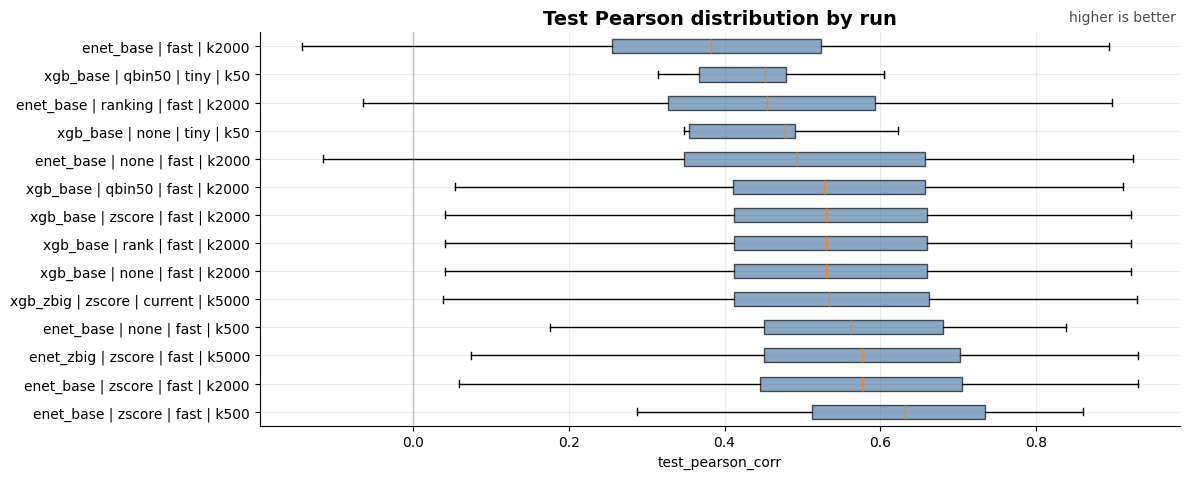

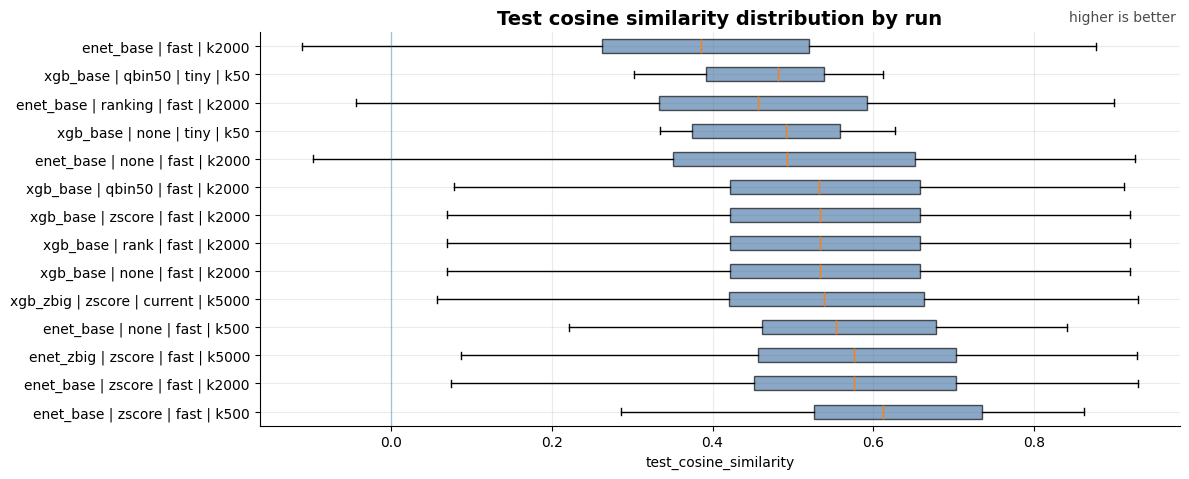

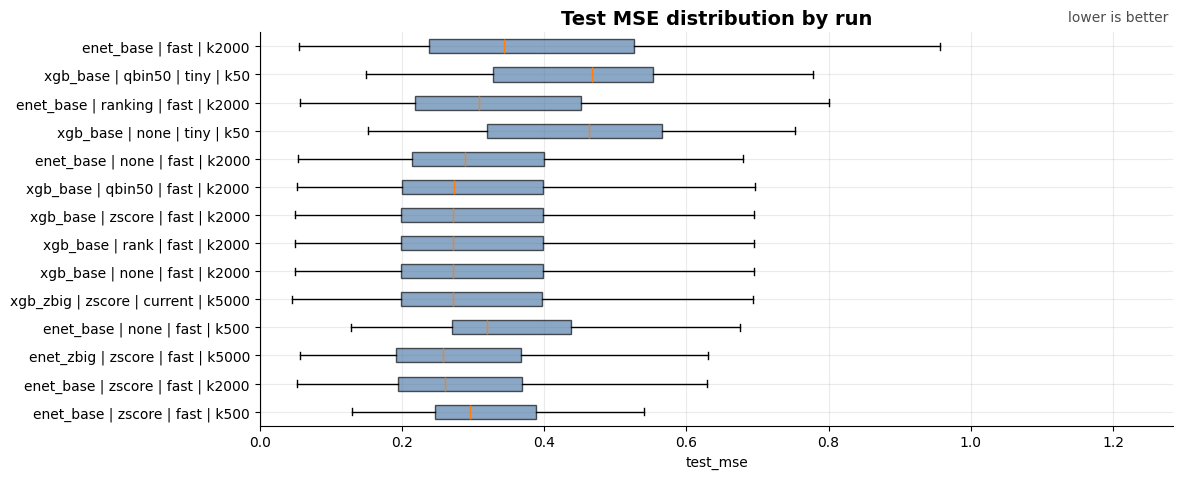

In [10]:
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

RUNS_ORDER = (
    results.groupby("run_label")["test_pearson_corr"]
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)


boxplot_metric(results, "test_pearson_corr", "Test Pearson distribution by run", True)
plt.show()
boxplot_metric(results, "test_cosine_similarity", "Test cosine similarity distribution by run", True)
plt.show()
fig, ax = boxplot_metric(results, "test_mse", "Test MSE distribution by run", False)
q99 = results["test_mse"].quantile(0.99)
if np.isfinite(q99):
    ax.set_xlim(left=0, right=q99)
plt.show()

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 4. Threshold summaries

The threshold table is printed rather than plotted. For MSE, if `MSE_GOOD_THRESHOLD = None`, the cutoff is the 25th percentile of the per-protein best MSE.

In [11]:
best_pearson = best_by_metric(results, "test_pearson_corr", higher=True)
best_cosine = best_by_metric(results, "test_cosine_similarity", higher=True)
best_mse = best_by_metric(results, "test_mse", higher=False)

if MSE_GOOD_THRESHOLD is None:
    mse_threshold = float(best_mse["test_mse"].quantile(0.25)) if len(best_mse) else np.nan
else:
    mse_threshold = float(MSE_GOOD_THRESHOLD)

print(f"Pearson good threshold: >= {PEARSON_GOOD_THRESHOLD}")
print(f"Cosine good threshold:  >= {COSINE_GOOD_THRESHOLD}")
print(f"MSE good threshold:     <= {mse_threshold:.4g}")

threshold_rows = []
for run_label, grp in results.groupby("run_label"):
    threshold_rows.append({
        "run_label": run_label,
        "proteins": grp["protein"].nunique(),
        "pearson_good_count": int((grp["test_pearson_corr"] >= PEARSON_GOOD_THRESHOLD).sum()),
        "cosine_good_count": int((grp["test_cosine_similarity"] >= COSINE_GOOD_THRESHOLD).sum()),
        "mse_good_count": int((grp["test_mse"] <= mse_threshold).sum()),
        "median_pearson": grp["test_pearson_corr"].median(),
        "median_cosine": grp["test_cosine_similarity"].median(),
        "median_mse": grp["test_mse"].median(),
    })
threshold_summary = pd.DataFrame(threshold_rows).sort_values("median_pearson", ascending=False)
display(threshold_summary)
threshold_summary.to_csv(OUT_DIR / "threshold_summary_by_run.csv", index=False)

print("Best possible per protein if we choose the best run by each metric:")
print("  Pearson:", len(best_pearson), "evaluated |", int((best_pearson["test_pearson_corr"] >= PEARSON_GOOD_THRESHOLD).sum()), "well predicted")
print("  Cosine: ", len(best_cosine), "evaluated |", int((best_cosine["test_cosine_similarity"] >= COSINE_GOOD_THRESHOLD).sum()), "well predicted")
print("  MSE:    ", len(best_mse), "evaluated |", int((best_mse["test_mse"] <= mse_threshold).sum()), "well predicted")

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Pearson good threshold: >= 0.7
Cosine good threshold:  >= 0.7
MSE good threshold:     <= 0.1829


,run_label,proteins,pearson_good_count,cosine_good_count,mse_good_count,median_pearson,median_cosine,median_mse
5,enet_base | zscore | fast | k500,50,20,18,3,0.631519,0.612456,0.295951
4,enet_base | zscore | fast | k2000,5113,1303,1306,1058,0.576582,0.576050,0.259997
6,enet_zbig | zscore | fast | k5000,5113,1302,1306,1144,0.576258,0.575982,0.257912
2,enet_base | none | fast | k500,50,10,12,3,0.561843,0.553677,0.319145
13,xgb_zbig | zscore | current | k5000,5113,966,976,1020,0.534373,0.538041,0.271998
7,xgb_base | none | fast | k2000,5113,951,951,1015,0.529856,0.534168,0.272304
11,xgb_base | rank | fast | k2000,5113,951,951,1015,0.529856,0.534168,0.272304
12,xgb_base | zscore | fast | k2000,5113,951,951,1015,0.529856,0.534168,0.272304
9,xgb_base | qbin50 | fast | k2000,5113,922,921,1007,0.527400,0.532045,0.273283
1,enet_base | none | fast | k2000,5113,991,998,786,0.493205,0.492372,0.288208


Best possible per protein if we choose the best run by each metric:
  Pearson: 5113 evaluated | 1418 well predicted
  Cosine:  5113 evaluated | 1428 well predicted
  MSE:     5113 evaluated | 1279 well predicted


## 5. Best run per protein

In [12]:
print("Best run per protein by Pearson:")
display(summarize_best(best_pearson, "test_pearson_corr", True, PEARSON_GOOD_THRESHOLD).head(20))
print("Best run per protein by cosine:")
display(summarize_best(best_cosine, "test_cosine_similarity", True, COSINE_GOOD_THRESHOLD).head(20))
print("Best run per protein by MSE:")
display(summarize_best(best_mse, "test_mse", False, mse_threshold).head(20))

best_pearson.to_csv(OUT_DIR / "best_per_protein_by_pearson.csv", index=False)
best_cosine.to_csv(OUT_DIR / "best_per_protein_by_cosine.csv", index=False)
best_mse.to_csv(OUT_DIR / "best_per_protein_by_mse.csv", index=False)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Best run per protein by Pearson:


,run_label,proteins,median_metric,mean_metric,good_proteins
0,enet_zbig | zscore | fast | k5000,1556,0.623793,0.613499,496
1,enet_base | zscore | fast | k2000,1424,0.614033,0.608614,415
2,xgb_zbig | zscore | current | k5000,614,0.559342,0.559532,139
3,xgb_base | qbin50 | fast | k2000,454,0.504555,0.516599,55
4,enet_base | none | fast | k2000,399,0.710512,0.666705,212
5,xgb_base | none | fast | k2000,175,0.547703,0.546763,29
6,xgb_base | zscore | fast | k2000,160,0.518916,0.522443,25
7,enet_base | ranking | fast | k2000,150,0.530723,0.529676,16
8,xgb_base | rank | fast | k2000,136,0.519351,0.523447,20
9,enet_base | fast | k2000,32,0.398271,0.465560,5


Best run per protein by cosine:


,run_label,proteins,median_metric,mean_metric,good_proteins
0,enet_zbig | zscore | fast | k5000,1588,0.621048,0.616291,498
1,enet_base | zscore | fast | k2000,1386,0.618076,0.611574,414
2,xgb_zbig | zscore | current | k5000,625,0.559021,0.561642,140
3,xgb_base | qbin50 | fast | k2000,459,0.514346,0.527268,53
4,enet_base | none | fast | k2000,396,0.714306,0.669007,218
5,xgb_base | none | fast | k2000,184,0.535538,0.533684,25
6,xgb_base | zscore | fast | k2000,169,0.553623,0.554390,30
7,enet_base | ranking | fast | k2000,142,0.543484,0.542998,21
8,xgb_base | rank | fast | k2000,116,0.508143,0.523577,17
9,enet_base | fast | k2000,34,0.438499,0.485823,6


Best run per protein by MSE:


,run_label,proteins,median_metric,mean_metric,good_proteins
0,enet_zbig | zscore | fast | k5000,1645,0.242283,0.284790,428
1,enet_base | zscore | fast | k2000,1053,0.264351,0.308744,195
2,xgb_zbig | zscore | current | k5000,733,0.235503,0.300791,206
3,xgb_base | qbin50 | fast | k2000,527,0.227788,0.277149,154
4,enet_base | none | fast | k2000,466,0.377112,0.446074,66
5,xgb_base | zscore | fast | k2000,192,0.222504,0.277533,66
6,xgb_base | none | fast | k2000,188,0.235364,0.281866,55
7,xgb_base | rank | fast | k2000,144,0.230431,0.281316,42
8,enet_base | ranking | fast | k2000,120,0.199361,0.264144,50
9,enet_base | fast | k2000,33,0.168842,0.203011,17


## 6. Protein partition plots

Each horizontal bar represents all proteins. Every segment shows how many proteins are best predicted by a model/run according to the chosen metric. Proteins whose best score is still below threshold are grouped into a red **Bad** segment.

Good-prediction thresholds:
  Pearson good if >= 0.70
  Cosine  good if >= 0.70
  MSE     good if <= 0.1829
  Individual model segments shown only if they contain >= 200 proteins

test_pearson_corr family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1418 (27.7%)
Bad proteins:  3695 (72.3%)
Good proteins best predicted by XGB:                268
Good proteins best predicted by ENet:               1150

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,496,0.773656
1,enet_base | zscore | fast | k2000,415,0.766896
2,enet_base | none | fast | k2000,212,0.803099
3,Other good models (<200 proteins each),295,0.787317
4,Bad / test_pearson_corr < 0.7,3695,0.533049



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
3,xgb_zbig | zscore | current | k5000,139,0.781317
4,xgb_base | qbin50 | fast | k2000,55,0.796665
5,xgb_base | none | fast | k2000,29,0.790705
6,xgb_base | zscore | fast | k2000,25,0.762441
7,xgb_base | rank | fast | k2000,20,0.783849
8,enet_base | ranking | fast | k2000,16,0.815694
9,enet_base | fast | k2000,5,0.810291
10,enet_base | zscore | fast | k500,5,0.726051
11,enet_base | none | fast | k500,1,0.807451


Saved: output\partition_best_by_pearson.png


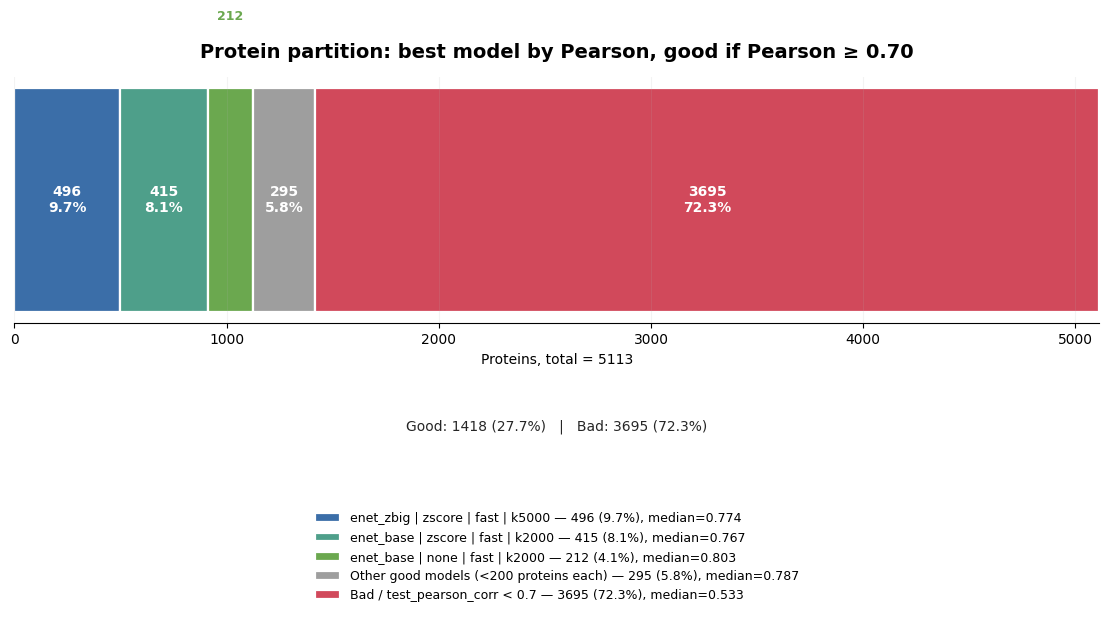


test_cosine_similarity family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1428 (27.9%)
Bad proteins:  3685 (72.1%)
Good proteins best predicted by XGB:                265
Good proteins best predicted by ENet:               1163

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,498,0.772878
1,enet_base | zscore | fast | k2000,414,0.766550
2,enet_base | none | fast | k2000,218,0.802352
3,Other good models (<200 proteins each),298,0.785693
4,Bad / test_cosine_similarity < 0.7,3685,0.538272



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
3,xgb_zbig | zscore | current | k5000,140,0.782079
4,xgb_base | qbin50 | fast | k2000,53,0.803460
5,xgb_base | zscore | fast | k2000,30,0.774233
6,xgb_base | none | fast | k2000,25,0.762342
7,enet_base | ranking | fast | k2000,21,0.808982
8,xgb_base | rank | fast | k2000,17,0.752550
9,enet_base | fast | k2000,6,0.764985
10,enet_base | zscore | fast | k500,5,0.752397
11,enet_base | none | fast | k500,1,0.804383


Saved: output\partition_best_by_cosine.png


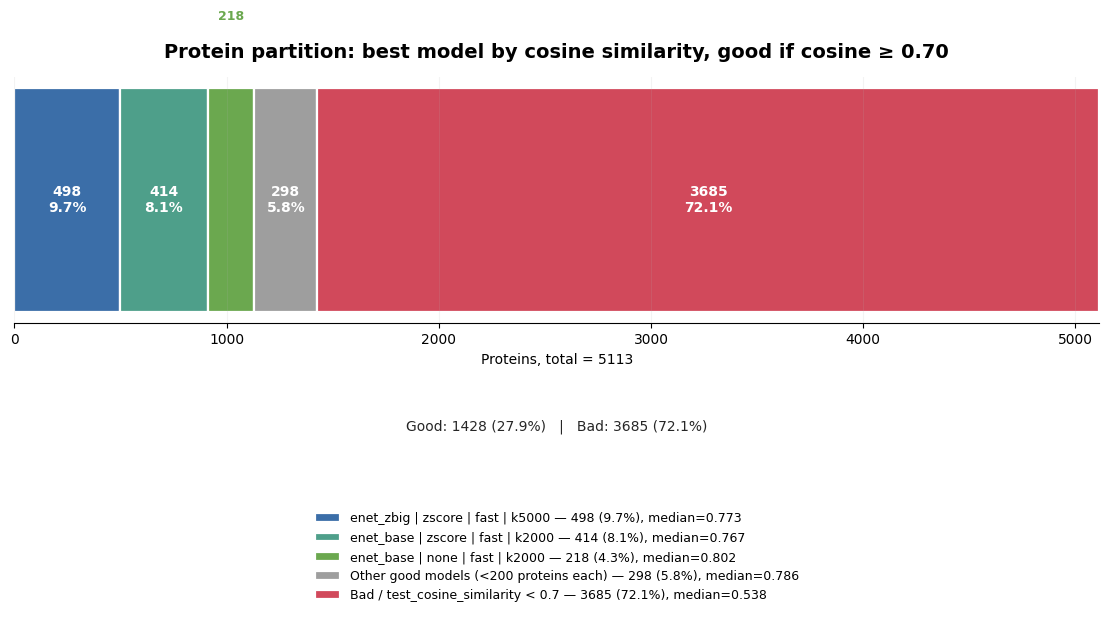


test_mse family summary
--------------------------------------------------------------------------------
Total proteins with valid metric: 5113
Good proteins: 1279 (25.0%)
Bad proteins:  3834 (75.0%)
Good proteins best predicted by XGB:                523
Good proteins best predicted by ENet:               756

Visible bar segments:


,partition_label,proteins,median_metric
0,enet_zbig | zscore | fast | k5000,428,0.150721
1,xgb_zbig | zscore | current | k5000,206,0.143190
2,Other good models (<200 proteins each),645,0.149053
3,Bad / test_mse > 0.182932,3834,0.293775



Hidden individual good segments with < 200 proteins:


,partition_label,proteins,median_metric
2,enet_base | zscore | fast | k2000,195,0.151947
3,xgb_base | qbin50 | fast | k2000,154,0.145917
4,enet_base | none | fast | k2000,66,0.154915
5,xgb_base | zscore | fast | k2000,66,0.144269
6,xgb_base | none | fast | k2000,55,0.150323
7,enet_base | ranking | fast | k2000,50,0.141737
8,xgb_base | rank | fast | k2000,42,0.155904
9,enet_base | fast | k2000,17,0.125288


Saved: output\partition_best_by_mse.png


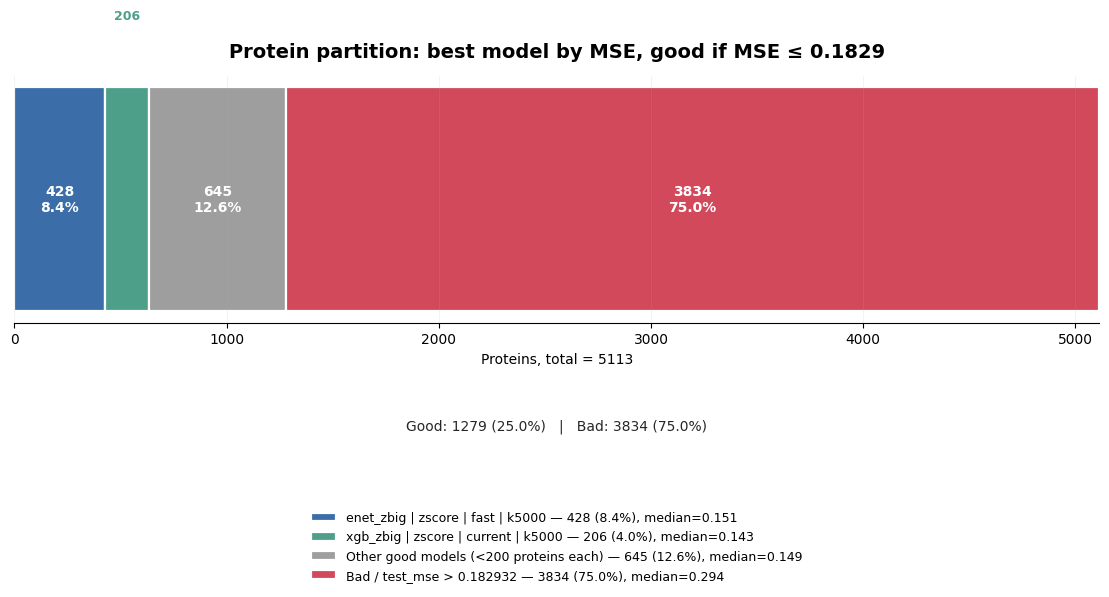

In [13]:
from pathlib import Path
from typing import Optional, Tuple
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ============================================================
# Output directory
# ============================================================
OUT_DIR = Path("./output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# Display and quality thresholds
# ============================================================
MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT = 200

# Pearson threshold:
# If previous threshold was already >= 0.5, raise to 0.7.
_previous_pearson = globals().get("PEARSON_GOOD_THRESHOLD", None)
if _previous_pearson is not None and float(_previous_pearson) >= 0.5:
    PEARSON_GOOD_THRESHOLD = 0.70
else:
    PEARSON_GOOD_THRESHOLD = 0.50

COSINE_GOOD_THRESHOLD = float(globals().get("COSINE_GOOD_THRESHOLD", 0.70))

# MSE threshold: lower is better.
# Keep existing threshold if it exists, otherwise use median of best-MSE results.
if "mse_threshold" not in globals():
    mse_threshold = float(best_mse["test_mse"].dropna().median())

print("Good-prediction thresholds:")
print(f"  Pearson good if >= {PEARSON_GOOD_THRESHOLD:.2f}")
print(f"  Cosine  good if >= {COSINE_GOOD_THRESHOLD:.2f}")
print(f"  MSE     good if <= {mse_threshold:.4g}")
print(f"  Individual model segments shown only if they contain >= {MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT} proteins")


# ============================================================
# Helpers
# ============================================================


# ============================================================
# Three partition plots
# ============================================================

partition_pearson = plot_partition_bar(
    best_pearson,
    metric="test_pearson_corr",
    threshold=PEARSON_GOOD_THRESHOLD,
    higher=True,
    title=f"Protein partition: best model by Pearson, good if Pearson ≥ {PEARSON_GOOD_THRESHOLD:.2f}",
    filename="partition_best_by_pearson.png",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

partition_cosine = plot_partition_bar(
    best_cosine,
    metric="test_cosine_similarity",
    threshold=COSINE_GOOD_THRESHOLD,
    higher=True,
    title=f"Protein partition: best model by cosine similarity, good if cosine ≥ {COSINE_GOOD_THRESHOLD:.2f}",
    filename="partition_best_by_cosine.png",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

partition_mse = plot_partition_bar(
    best_mse,
    metric="test_mse",
    threshold=mse_threshold,
    higher=False,
    title=f"Protein partition: best model by MSE, good if MSE ≤ {mse_threshold:.4g}",
    filename="partition_best_by_mse.png",
    min_proteins_to_show=MIN_PROTEINS_TO_SHOW_AS_OWN_SEGMENT,
)

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

## 7. Optional: inspect one best model artifact

In [14]:
if len(best_pearson) == 0:
    print("No best result available.")
else:
    example_path = Path(best_pearson.iloc[0]["h5_path"])
    print("Example H5 selected:", example_path)
    try:
        artifact = load_artifact_from_h5(example_path)
        with h5py.File(example_path, "r") as h5:
            summary = read_json_dataset(h5, ["summary/json", "metrics/json"])
        print("Protein:", summary.get("protein", example_path.stem.split("_")[0]))
        print("Test MSE:", summary.get("test_mse"))
        print("Test Pearson:", summary.get("test_pearson_corr"))
        print("Test cosine:", summary.get("test_cosine_similarity"))
        selected = summary.get("selected_features", None)
        if selected is None and artifact is not None:
            selected = artifact.get("selected_features", [])
        selected = selected or []
        print("Selected features:", len(selected))
        print("First 20 selected features:", selected[:20])
        if artifact is not None:
            model = artifact.get("model")
            print("Artifact kind:", artifact.get("artifact_kind"))
            print("Model class:", type(model))
            print("Normalization:", artifact.get("normalization"))
            print("Params:")
            print(json.dumps(summary.get("best_params", artifact.get("params", {})), indent=2, default=str))
            if hasattr(model, "coef_"):
                weights = pd.DataFrame({"gene": artifact.get("selected_features", []), "coef": model.coef_})
                weights["abs_coef"] = weights["coef"].abs()
                weights_nonzero = weights[weights["coef"] != 0].sort_values("abs_coef", ascending=False).drop(columns="abs_coef")
                print("Total coefficients:", len(weights))
                print("Nonzero coefficients:", len(weights_nonzero))
                display(weights_nonzero.head(30))
    except Exception as e:
        print("Could not inspect model artifact:", repr(e))

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Example H5 selected: c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. ccle_res_analysis\data\results_enet\CAMK2D_enet_8020_zscore_fast_k2000.h5
Could not inspect model artifact: ModuleNotFoundError("No module named 'numpy._core.numeric'")


## 8. Export compact best-model table

In [15]:
wide_best = pd.DataFrame({"protein": sorted(results["protein"].unique())})
for name, best_df, metric in [
    ("pearson", best_pearson, "test_pearson_corr"),
    ("cosine", best_cosine, "test_cosine_similarity"),
    ("mse", best_mse, "test_mse"),
]:
    tmp = best_df[["protein", "run_label", metric, "h5_path"]].rename(columns={
        "run_label": f"best_{name}_run",
        metric: f"best_{name}_score",
        "h5_path": f"best_{name}_h5_path",
    })
    wide_best = wide_best.merge(tmp, on="protein", how="left")

wide_best.to_csv(OUT_DIR / "best_model_per_protein_all_metrics.csv", index=False)
print("Saved:", OUT_DIR / "best_model_per_protein_all_metrics.csv")
display(wide_best.head())

# Keep moved utility functions synchronized with notebook variables.
try:
    uc.set_module_globals(globals())
except NameError:
    pass

Saved: output\best_model_per_protein_all_metrics.csv


,protein,best_pearson_run,best_pearson_score,best_pearson_h5_path,best_cosine_run,best_cosine_score,best_cosine_h5_path,best_mse_run,best_mse_score,best_mse_h5_path
0,A2M,enet_base | ranking | fast | k2000,0.492897,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | ranking | fast | k2000,0.573536,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | ranking | fast | k2000,0.733483,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
1,AAAS,enet_base | zscore | fast | k2000,0.637295,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | zscore | fast | k2000,0.646450,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | zscore | fast | k2000,0.102694,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2,AACS,enet_base | zscore | fast | k2000,0.675858,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | zscore | fast | k2000,0.668078,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | zscore | fast | k2000,0.357902,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3,AAGAB,enet_base | none | fast | k500,0.475606,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | none | fast | k500,0.465451,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | none | fast | k500,0.450723,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
4,AAK1,enet_base | zscore | fast | k2000,0.730509,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | zscore | fast | k2000,0.735883,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...,enet_base | zscore | fast | k2000,0.261418,c:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
